# Evaluación, interpretabilidad y análisis crítico

**CNNs vs Transformers para clasificación de melanoma (ISIC 2020)**

Este notebook usa lo que guardó `02_entrenamiento.ipynb` (probabilidades predichas, historiales y checkpoints) para:

1. **Elegir el umbral de decisión en validación** y reportar las métricas finales en **prueba**: Accuracy, F1, AUC, sensibilidad y especificidad, con intervalos de confianza.
2. Comparar curvas ROC y Precision-Recall, y matrices de confusión.
3. Consolidar el **costo computacional** y la **facilidad de convergencia**.
4. **Interpretabilidad:** Grad-CAM para las CNNs y para ViT, y mapas de atención (*attention rollout*) para ViT.
5. **Análisis crítico** y mejoras futuras.

In [1]:
## Standard libraries
import os
import json
import numpy as np
import pandas as pd

## Imports for plotting
import matplotlib.pyplot as plt
%matplotlib inline
from matplotlib_inline.backend_inline import set_matplotlib_formats
set_matplotlib_formats('svg', 'pdf') # For export
import seaborn as sns
sns.set()

## PyTorch
import torch
import torch.nn as nn
import torch.nn.functional as F
## Torchvision
from torchvision import transforms, models

## Métricas
from sklearn.metrics import roc_curve, precision_recall_curve, average_precision_score, roc_auc_score, f1_score
from PIL import Image

## Utilidades del proyecto (dataset y métricas)
from isic_utils import compute_metrics, best_f1_threshold

## Progress bar
from tqdm.notebook import tqdm

In [ ]:
DATASET_PATH = r"C:\datasets\isic2020"
CHECKPOINT_PATH = "saved_models"
RESULTS_PATH = "results"

QUICK_TEST = False
if QUICK_TEST:
    CHECKPOINT_PATH, RESULTS_PATH = "saved_models_test", "results_test"

MODEL_NAMES = ["ResNet50", "DenseNet121", "ViT_B16"]
MODEL_LABELS = {"ResNet50": "ResNet-50", "DenseNet121": "DenseNet-121", "ViT_B16": "ViT-B/16"}
MODEL_COLORS = {"ResNet50": "#2a78d6", "DenseNet121": "#eb6834", "ViT_B16": "#1baf7a"}

device = torch.device("cuda:0") if torch.cuda.is_available() else torch.device("cpu")

preds = {m: pd.read_csv(os.path.join(RESULTS_PATH, f"preds_{m}.csv")) for m in MODEL_NAMES}
for m in MODEL_NAMES:
    p = preds[m]
    print(f"{MODEL_LABELS[m]:13s}: val {(p.split == 'val').sum():,} | test {(p.split == 'test').sum():,}")

ResNet-50    : val 4,910 | test 4,902
DenseNet-121 : val 4,910 | test 4,902
ViT-B/16     : val 4,910 | test 4,902


## 1. Umbral de decisión y métricas en prueba

Con ~1.8 % de melanomas, el umbral por defecto (0.5) no es adecuado: el `pos_weight` de la pérdida desplaza las probabilidades y el umbral que maximiza F1 suele ser otro. Procedimiento:

1. En **validación**, se busca el umbral que maximiza el F1 de la clase melanoma.
2. Ese umbral se aplica, sin cambios, al conjunto de **prueba**.

Se reporta también el resultado con umbral 0.5 como referencia. La **AUC no depende del umbral**.

In [3]:
thresholds = {}
rows = []
for m in MODEL_NAMES:
    p = preds[m]
    val, test = p[p.split == "val"], p[p.split == "test"]
    thresholds[m], _ = best_f1_threshold(val.target, val.prob)
    for label, thr in [("0.5", 0.5), ("óptimo en val", thresholds[m])]:
        r = compute_metrics(test.target, test.prob, threshold=thr)
        rows.append({"modelo": MODEL_LABELS[m], "umbral": label, **r})

metrics_test = pd.DataFrame(rows)
cols = ["modelo", "umbral", "threshold", "accuracy", "balanced_accuracy", "f1", "sensitivity", "specificity", "auc", "tp", "fp", "fn", "tn"]
metrics_test[cols].round(4)

,modelo,umbral,threshold,accuracy,balanced_accuracy,f1,sensitivity,specificity,auc,tp,fp,fn,tn
0,ResNet-50,0.5,0.5000,0.8305,0.8133,0.1442,0.7955,0.8311,0.8897,70,813,18,4001
1,ResNet-50,óptimo en val,0.9237,0.9549,0.6591,0.2191,0.3523,0.9659,0.8897,31,164,57,4650
2,DenseNet-121,0.5,0.5000,0.8443,0.8482,0.1643,0.8523,0.8442,0.9217,75,750,13,4064
3,DenseNet-121,óptimo en val,0.8618,0.9525,0.6802,0.2310,0.3977,0.9626,0.9217,35,180,53,4634
4,ViT-B/16,0.5,0.5000,0.8313,0.8527,0.1570,0.8750,0.8305,0.9201,77,816,11,3998
5,ViT-B/16,óptimo en val,0.9327,0.9684,0.7050,0.3290,0.4318,0.9782,0.9201,38,105,50,4709


### Intervalos de confianza

El conjunto de prueba tiene solo ~88 melanomas, así que las métricas tienen bastante incertidumbre. Estimamos intervalos de confianza del 95 % remuestreando el conjunto de prueba con reemplazo (1,000 veces). Usamos **los mismos remuestreos para los tres modelos**, lo que permite comparar las diferencias entre pares: si el intervalo de la diferencia incluye el 0, la diferencia no es concluyente.

In [4]:
N_BOOT = 1000
rng = np.random.default_rng(42)
test_ref = preds[MODEL_NAMES[0]].query("split == 'test'").reset_index(drop=True)
y_test = test_ref.target.values
prob_test = {m: preds[m].query("split == 'test'").reset_index(drop=True).prob.values for m in MODEL_NAMES}
for m in MODEL_NAMES:  # mismas imágenes y mismo orden en todos los archivos
    assert (preds[m].query("split == 'test'").image_name.values == test_ref.image_name.values).all()

boot = {m: {"auc": [], "f1": []} for m in MODEL_NAMES}
for _ in tqdm(range(N_BOOT)):
    idx = rng.integers(0, len(y_test), len(y_test))
    y = y_test[idx]
    if y.min() == y.max():
        continue
    for m in MODEL_NAMES:
        p = prob_test[m][idx]
        boot[m]["auc"].append(roc_auc_score(y, p))
        boot[m]["f1"].append(f1_score(y, p >= thresholds[m]))

ci = lambda v: f"[{np.percentile(v, 2.5):.3f}, {np.percentile(v, 97.5):.3f}]"
pd.DataFrame({MODEL_LABELS[m]: {"AUC": f"{roc_auc_score(y_test, prob_test[m]):.3f}",
                                "AUC IC 95%": ci(boot[m]["auc"]),
                                "F1": f"{f1_score(y_test, prob_test[m] >= thresholds[m]):.3f}",
                                "F1 IC 95%": ci(boot[m]["f1"])} for m in MODEL_NAMES}).T

  0%|          | 0/1000 [00:00<?, ?it/s]

,AUC,AUC IC 95%,F1,F1 IC 95%
ResNet-50,0.890,"[0.856, 0.919]",0.219,"[0.150, 0.284]"
DenseNet-121,0.922,"[0.901, 0.941]",0.231,"[0.165, 0.295]"
ViT-B/16,0.920,"[0.895, 0.943]",0.329,"[0.249, 0.407]"


In [5]:
pairs = [(a, b) for i, a in enumerate(MODEL_NAMES) for b in MODEL_NAMES[i + 1:]]
diff_rows = []
for a, b in pairs:
    d_auc = np.array(boot[a]["auc"]) - np.array(boot[b]["auc"])
    d_f1 = np.array(boot[a]["f1"]) - np.array(boot[b]["f1"])
    diff_rows.append({"comparación": f"{MODEL_LABELS[a]} − {MODEL_LABELS[b]}",
                      "Δ AUC": f"{d_auc.mean():+.3f}", "Δ AUC IC 95%": ci(d_auc),
                      "Δ F1": f"{d_f1.mean():+.3f}", "Δ F1 IC 95%": ci(d_f1)})
pd.DataFrame(diff_rows).set_index("comparación")

,Δ AUC,Δ AUC IC 95%,Δ F1,Δ F1 IC 95%
comparación,,,,
ResNet-50 − DenseNet-121,-0.031,"[-0.062, -0.007]",-0.011,"[-0.063, 0.040]"
ResNet-50 − ViT-B/16,-0.030,"[-0.055, -0.005]",-0.108,"[-0.174, -0.043]"
DenseNet-121 − ViT-B/16,+0.002,"[-0.016, 0.019]",-0.097,"[-0.157, -0.034]"


## 2. Curvas ROC y Precision-Recall (prueba)

- **ROC:** sensibilidad vs. tasa de falsos positivos para todos los umbrales. Con clases muy desbalanceadas puede verse optimista, porque los verdaderos negativos son abundantes.
- **Precision-Recall:** más informativa con desbalance. La línea punteada es la precisión de un clasificador aleatorio (= prevalencia ≈ 1.8 %). El área bajo esta curva es la *average precision* (AP).

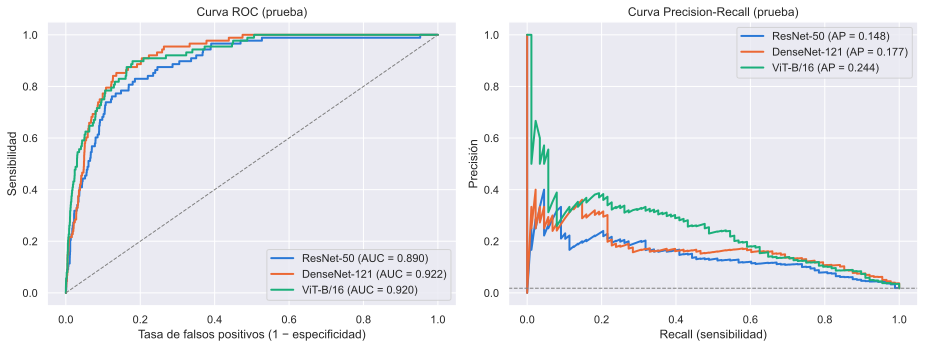

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for m in MODEL_NAMES:
    fpr, tpr, _ = roc_curve(y_test, prob_test[m])
    prec, rec, _ = precision_recall_curve(y_test, prob_test[m])
    axes[0].plot(fpr, tpr, color=MODEL_COLORS[m], lw=2, label=f"{MODEL_LABELS[m]} (AUC = {roc_auc_score(y_test, prob_test[m]):.3f})")
    axes[1].plot(rec, prec, color=MODEL_COLORS[m], lw=2, label=f"{MODEL_LABELS[m]} (AP = {average_precision_score(y_test, prob_test[m]):.3f})")
axes[0].plot([0, 1], [0, 1], color="gray", ls="--", lw=1)
axes[1].axhline(y_test.mean(), color="gray", ls="--", lw=1)
axes[0].set(xlabel="Tasa de falsos positivos (1 − especificidad)", ylabel="Sensibilidad", title="Curva ROC (prueba)")
axes[1].set(xlabel="Recall (sensibilidad)", ylabel="Precisión", title="Curva Precision-Recall (prueba)")
for ax in axes:
    ax.legend(loc="lower right" if ax is axes[0] else "upper right")
plt.tight_layout()
plt.savefig(os.path.join(RESULTS_PATH, "roc_pr_test.pdf"), bbox_inches="tight")
plt.show()

## 3. Matrices de confusión (prueba, umbral elegido en validación)

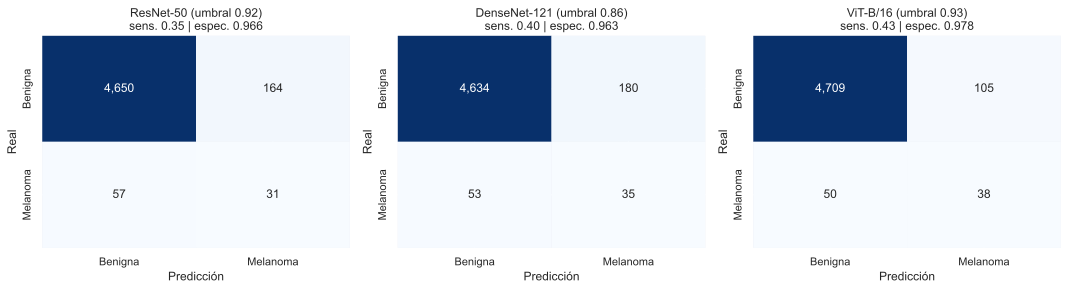

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))
for ax, m in zip(axes, MODEL_NAMES):
    r = compute_metrics(y_test, prob_test[m], threshold=thresholds[m])
    cm = np.array([[r["tn"], r["fp"]], [r["fn"], r["tp"]]])
    sns.heatmap(cm, annot=True, fmt=",d", cmap="Blues", cbar=False, ax=ax,
                xticklabels=["Benigna", "Melanoma"], yticklabels=["Benigna", "Melanoma"])
    ax.set(xlabel="Predicción", ylabel="Real",
           title=f"{MODEL_LABELS[m]} (umbral {thresholds[m]:.2f})\nsens. {r['sensitivity']:.2f} | espec. {r['specificity']:.3f}")
plt.tight_layout()
plt.savefig(os.path.join(RESULTS_PATH, "matrices_confusion_test.pdf"), bbox_inches="tight")
plt.show()

## Ensambles de modelos (variante adicional)

Un **ensamble** combina las predicciones de varios modelos. Usamos el más simple, el **promedio de probabilidades** (*soft voting*):

$$p_{\text{ens}}(x) = \frac{1}{K}\sum_{k=1}^{K} p_k(x)$$

No requiere reentrenar: se calcula con las probabilidades ya guardadas en `results/preds_*.csv`. Definimos de antemano dos variantes, para no elegir combinaciones mirando el conjunto de prueba:

- **Ensamble CNN** (ResNet-50 + DenseNet-121): ¿combinar dos CNNs mejora a la mejor de ellas?
- **Ensamble 3** (ResNet-50 + DenseNet-121 + ViT-B/16): ¿agregar el Transformer aporta información que las CNNs no tienen?

El umbral de cada ensamble se elige igual que el de los modelos individuales: maximizando el F1 en **validación**.

In [ ]:
ENSEMBLES = {"Ens_CNN": ["ResNet50", "DenseNet121"],
             "Ens_3": ["ResNet50", "DenseNet121", "ViT_B16"]}
ENS_LABELS = {"Ens_CNN": "Ensamble CNN", "Ens_3": "Ensamble 3"}
ALL_MODELS = MODEL_NAMES + list(ENSEMBLES)
ALL_LABELS = {**MODEL_LABELS, **ENS_LABELS}

val_ref = preds[MODEL_NAMES[0]].query("split == 'val'").reset_index(drop=True)
y_val = val_ref.target.values
prob_val = {m: preds[m].query("split == 'val'").reset_index(drop=True).prob.values for m in MODEL_NAMES}

for e, members in ENSEMBLES.items():
    prob_val[e] = np.mean([prob_val[m] for m in members], axis=0)
    prob_test[e] = np.mean([prob_test[m] for m in members], axis=0)
    thresholds[e], _ = best_f1_threshold(y_val, prob_val[e])

ens_rows = []
for m in ALL_MODELS:
    r = compute_metrics(y_test, prob_test[m], threshold=thresholds[m])
    _, f1_val = best_f1_threshold(y_val, prob_val[m])
    ens_rows.append({"modelo": ALL_LABELS[m], "umbral": thresholds[m],
                     "AUC val": roc_auc_score(y_val, prob_val[m]), "F1 val": f1_val,
                     "AUC test": r["auc"], "AP test": average_precision_score(y_test, prob_test[m]),
                     "F1 test": r["f1"], "Accuracy test": r["accuracy"],
                     "Sensibilidad": r["sensitivity"], "Especificidad": r["specificity"],
                     "VP": r["tp"], "FP": r["fp"], "FN": r["fn"]})
ensemble_table = pd.DataFrame(ens_rows).set_index("modelo")
ensemble_table.to_csv(os.path.join(RESULTS_PATH, "tabla_ensambles.csv"))
ensemble_table.round(4)

### Intervalos de confianza y comparaciones pareadas

Repetimos el *bootstrap* con la **misma semilla** que en la sección 1, por lo que los intervalos de los modelos individuales coinciden exactamente con los anteriores y las comparaciones con los ensambles son pareadas.

In [ ]:
rng = np.random.default_rng(42)
boot_all = {m: {"auc": [], "f1": []} for m in ALL_MODELS}
for _ in tqdm(range(N_BOOT)):
    idx = rng.integers(0, len(y_test), len(y_test))
    y = y_test[idx]
    if y.min() == y.max():
        continue
    for m in ALL_MODELS:
        p = prob_test[m][idx]
        boot_all[m]["auc"].append(roc_auc_score(y, p))
        boot_all[m]["f1"].append(f1_score(y, p >= thresholds[m]))

ens_pairs = [("Ens_3", "ResNet50"), ("Ens_3", "DenseNet121"), ("Ens_3", "ViT_B16"),
             ("Ens_CNN", "DenseNet121"), ("Ens_3", "Ens_CNN")]
rows = []
for a, b in ens_pairs:
    d_auc = np.array(boot_all[a]["auc"]) - np.array(boot_all[b]["auc"])
    d_f1 = np.array(boot_all[a]["f1"]) - np.array(boot_all[b]["f1"])
    rows.append({"comparación": f"{ALL_LABELS[a]} − {ALL_LABELS[b]}",
                 "Δ AUC": f"{d_auc.mean():+.3f}", "Δ AUC IC 95%": ci(d_auc),
                 "Δ F1": f"{d_f1.mean():+.3f}", "Δ F1 IC 95%": ci(d_f1)})
pd.DataFrame(rows).set_index("comparación")

### ¿Por qué combinar modelos puede ayudar? Diversidad de los errores

Un ensamble solo mejora si sus miembros se equivocan en casos distintos. Medimos la correlación de Spearman entre las probabilidades de cada par de modelos y cuántos melanomas detecta cada uno (con su propio umbral).

In [ ]:
from scipy.stats import spearmanr

corr = pd.DataFrame(index=[MODEL_LABELS[m] for m in MODEL_NAMES], columns=[MODEL_LABELS[m] for m in MODEL_NAMES], dtype=float)
for a in MODEL_NAMES:
    for b in MODEL_NAMES:
        corr.loc[MODEL_LABELS[a], MODEL_LABELS[b]] = spearmanr(prob_test[a], prob_test[b]).correlation
display(corr.round(3))

detected = {m: set(np.where((prob_test[m] >= thresholds[m]) & (y_test == 1))[0]) for m in MODEL_NAMES}
print("Melanomas detectados por cada modelo:", {MODEL_LABELS[m]: len(d) for m, d in detected.items()})
print(f"Detectados por al menos uno: {len(set.union(*detected.values()))} de {int(y_test.sum())}")
print(f"Detectados por los tres:     {len(set.intersection(*detected.values()))}")

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for m in ["DenseNet121", "ViT_B16", "Ens_CNN", "Ens_3"]:
    color = MODEL_COLORS.get(m, {"Ens_CNN": "#898781", "Ens_3": "#4a3aa7"}.get(m))
    ls = "-" if m in MODEL_NAMES else "--"
    fpr, tpr, _ = roc_curve(y_test, prob_test[m])
    prec, rec, _ = precision_recall_curve(y_test, prob_test[m])
    axes[0].plot(fpr, tpr, color=color, ls=ls, lw=2, label=f"{ALL_LABELS[m]} (AUC = {roc_auc_score(y_test, prob_test[m]):.3f})")
    axes[1].plot(rec, prec, color=color, ls=ls, lw=2, label=f"{ALL_LABELS[m]} (AP = {average_precision_score(y_test, prob_test[m]):.3f})")
axes[0].plot([0, 1], [0, 1], color="gray", ls=":", lw=1)
axes[1].axhline(y_test.mean(), color="gray", ls=":", lw=1)
axes[0].set(xlabel="Tasa de falsos positivos", ylabel="Sensibilidad", title="ROC (prueba): ensambles")
axes[1].set(xlabel="Recall", ylabel="Precisión", title="Precision-Recall (prueba): ensambles")
axes[0].legend(loc="lower right")
axes[1].legend(loc="upper right")
plt.tight_layout()
plt.savefig(os.path.join(RESULTS_PATH, "roc_pr_ensambles.pdf"), bbox_inches="tight")
plt.show()

### Interpretación

- **El Ensamble 3 obtiene el mayor AUC** (0.928 en prueba y 0.927 en validación). Es significativamente mejor que ResNet-50 y que el Ensamble CNN, aunque no que DenseNet-121 ni ViT-B/16 por separado.
- **Agregar el Transformer es lo que aporta**: el Ensamble CNN no mejora a DenseNet-121 (sus predicciones están muy correlacionadas, 0.873), mientras que ViT-B/16 está menos correlacionado con las CNNs (0.80–0.84) y aporta información complementaria. Entre los tres modelos detectan 48 melanomas distintos, frente a un máximo de 38 de un solo modelo.
- **El F1 del ensamble no supera al de ViT-B/16.** En validación el Ensamble 3 sí tuvo el mejor F1, pero su umbral óptimo es muy conservador (marca solo ~1 % de las imágenes como melanoma), por lo que el F1 depende de muy pocos casos y no se trasladó bien a prueba (sensibilidad 21.6 %, especificidad 99.1 %). Con ~89 melanomas en validación, las métricas que dependen del umbral son inestables; el AUC, que no depende de él, es la evidencia más sólida de la mejora.
- **Costo:** el ensamble no requiere entrenamiento adicional, pero la inferencia cuesta la suma de los tres modelos.

## 4. Costo computacional y facilidad de convergencia

Datos registrados durante el entrenamiento (notebook 02).

In [8]:
histories = {m: pd.read_csv(os.path.join(RESULTS_PATH, f"history_{m}.csv")) for m in MODEL_NAMES}
infos = {m: json.load(open(os.path.join(RESULTS_PATH, f"train_info_{m}.json"))) for m in MODEL_NAMES}

final_rows = []
for m in MODEL_NAMES:
    h, info = histories[m], infos[m]
    r = compute_metrics(y_test, prob_test[m], threshold=thresholds[m])
    final_rows.append({"modelo": MODEL_LABELS[m],
                       "AUC test": round(r["auc"], 4),
                       "F1 test": round(r["f1"], 4),
                       "Accuracy test": round(r["accuracy"], 4),
                       "Sensibilidad": round(r["sensitivity"], 3),
                       "Especificidad": round(r["specificity"], 3),
                       "Parámetros (M)": round(info["params_M"], 1),
                       "Min / época": round(info["mean_epoch_time_min"], 1),
                       "Tiempo total (min)": round(info["train_time_min"], 1),
                       "Memoria GPU (GB)": round(info["peak_gpu_mem_gb"], 2),
                       "Época 95% mejor AUC": int(h.loc[h.val_auc >= 0.95 * h.val_auc.max(), "epoch"].min()),
                       "Mejor época": info["best_epoch"],
                       "Épocas entrenadas": info["epochs_trained"]})
final_table = pd.DataFrame(final_rows).set_index("modelo")
final_table.to_csv(os.path.join(RESULTS_PATH, "tabla_final.csv"))
final_table

,AUC test,F1 test,Accuracy test,Sensibilidad,Especificidad,Parámetros (M),Min / época,Tiempo total (min),Memoria GPU (GB),Época 95% mejor AUC,Mejor época,Épocas entrenadas
modelo,,,,,,,,,,,,
ResNet-50,0.8897,0.2191,0.9549,0.352,0.966,23.5,3.8,59.1,1.10,1,14,15
DenseNet-121,0.9217,0.2310,0.9525,0.398,0.963,7.0,5.2,78.8,1.16,3,14,15
ViT-B/16,0.9201,0.3290,0.9684,0.432,0.978,85.8,10.9,120.7,2.58,1,6,11


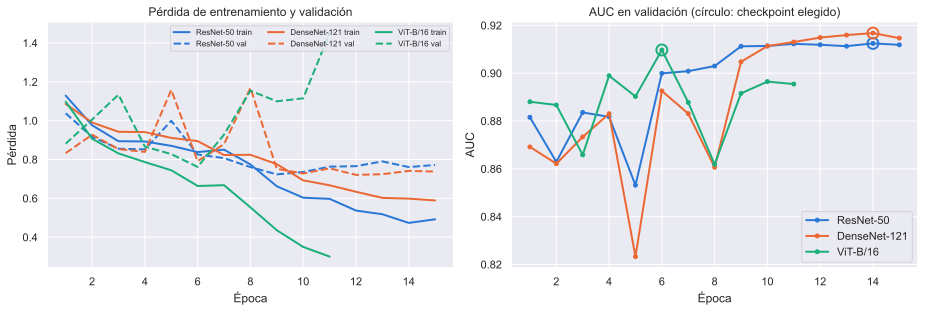

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for m in MODEL_NAMES:
    h, c = histories[m], MODEL_COLORS[m]
    axes[0].plot(h.epoch, h.train_loss, color=c, lw=2, label=f"{MODEL_LABELS[m]} train")
    axes[0].plot(h.epoch, h.val_loss, color=c, lw=2, ls="--", label=f"{MODEL_LABELS[m]} val")
    axes[1].plot(h.epoch, h.val_auc, color=c, lw=2, marker="o", ms=4, label=MODEL_LABELS[m])
    best = h.val_auc.idxmax()
    axes[1].scatter(h.epoch[best], h.val_auc[best], s=120, facecolors="none", edgecolors=c, lw=2)
axes[0].set(xlabel="Época", ylabel="Pérdida", title="Pérdida de entrenamiento y validación")
axes[1].set(xlabel="Época", ylabel="AUC", title="AUC en validación (círculo: checkpoint elegido)")
axes[0].legend(fontsize=8, ncol=3)
axes[1].legend()
plt.tight_layout()
plt.savefig(os.path.join(RESULTS_PATH, "convergencia.pdf"), bbox_inches="tight")
plt.show()

## 5. ¿Aprenden la lesión o el equipo?

En el notebook 01 vimos que la tasa de melanoma cambia muchísimo según la resolución original de la imagen (es decir, según el equipo o la clínica de origen). Si un modelo aprovecha ese atajo, su AUC **dentro** de cada grupo de resolución será bastante menor que su AUC global: separaría bien los grupos, pero no las lesiones dentro de un mismo grupo.

In [10]:
meta = pd.read_csv(os.path.join(DATASET_PATH, "train_256_split.csv"))[["image_name", "orig_width", "orig_height"]]
test_meta = test_ref.merge(meta, on="image_name")
test_meta["resolution"] = test_meta.orig_width.astype(str) + "×" + test_meta.orig_height.astype(str)
for m in MODEL_NAMES:
    test_meta[m] = prob_test[m]

group_rows = []
for res, g in test_meta.groupby("resolution"):
    if g.target.sum() < 5 or g.target.sum() == len(g):
        continue
    row = {"resolución": res, "imágenes": len(g), "melanomas": int(g.target.sum())}
    row.update({f"AUC {MODEL_LABELS[m]}": round(roc_auc_score(g.target, g[m]), 3) for m in MODEL_NAMES})
    group_rows.append(row)
row = {"resolución": "GLOBAL", "imágenes": len(test_meta), "melanomas": int(test_meta.target.sum())}
row.update({f"AUC {MODEL_LABELS[m]}": round(roc_auc_score(test_meta.target, test_meta[m]), 3) for m in MODEL_NAMES})
group_rows.append(row)
pd.DataFrame(group_rows).set_index("resolución")

,imágenes,melanomas,AUC ResNet-50,AUC DenseNet-121,AUC ViT-B/16
resolución,,,,,
1872×1053,1205,15,0.827,0.862,0.853
2592×1936,87,12,0.637,0.722,0.838
3264×2448,227,17,0.881,0.870,0.883
5184×3456,498,9,0.921,0.954,0.938
640×480,647,17,0.889,0.873,0.883
GLOBAL,4902,88,0.890,0.922,0.920


Solo se muestran grupos con al menos 5 melanomas en prueba; con tan pocos positivos por grupo, las AUC por grupo son ruidosas y deben leerse como indicio, no como prueba.

## 6. Interpretabilidad

Usamos dos técnicas:

- **Grad-CAM** (Selvaraju et al., 2017): toma los mapas de activación de una capa profunda y los pondera por el gradiente promedio del logit de melanoma respecto a cada canal. El resultado indica **qué regiones aumentan la predicción de melanoma**. En las CNNs se aplica a la última etapa convolucional (mapa de 7×7). En ViT se aplica a los tokens del último bloque, reorganizados en la cuadrícula de 14×14 parches.
- **Attention rollout** (Abnar & Zuidema, 2020), solo para ViT: combina las matrices de atención de los 12 bloques (promediando las cabezas y sumando la identidad por las conexiones residuales) para estimar **cuánto atiende el token `[CLS]` a cada parche** de la imagen. A diferencia de Grad-CAM, no depende de la clase: muestra a dónde mira el modelo, no qué evidencia usa a favor de melanoma.

### Cargar los modelos entrenados

Reconstruimos cada arquitectura con la misma última capa que en el notebook 02 y cargamos los pesos del checkpoint.

In [11]:
def ResNet50(num_classes=1, pretrained=False):
    model = models.resnet50(weights=None)
    model.fc = nn.Linear(model.fc.in_features, num_classes)
    return model

def DenseNet121(num_classes=1, pretrained=False):
    model = models.densenet121(weights=None)
    model.classifier = nn.Linear(model.classifier.in_features, num_classes)
    return model

def ViT_B16(num_classes=1, pretrained=False):
    model = models.vit_b_16(weights=None)
    model.heads.head = nn.Linear(model.heads.head.in_features, num_classes)
    return model

model_dict = {"ResNet50": ResNet50, "DenseNet121": DenseNet121, "ViT_B16": ViT_B16}

def load_model(model_name):
    model = model_dict[model_name]()
    ckpt = torch.load(os.path.join(CHECKPOINT_PATH, f"{model_name}.ckpt"), map_location="cpu", weights_only=False)
    # Los pesos del LightningModule tienen el prefijo "model." (atributo self.model de ISICModule)
    state = {k[len("model."):]: v for k, v in ckpt["state_dict"].items() if k.startswith("model.")}
    model.load_state_dict(state)
    return model.eval().to(device)

trained = {m: load_model(m) for m in MODEL_NAMES}

### Grad-CAM y attention rollout

Implementados con *hooks* de PyTorch (sin librerías externas):
- Un *forward hook* guarda las activaciones de la capa objetivo y registra un hook en ese tensor para guardar su gradiente durante `backward()`.
- Para ViT, un *forward pre-hook* fuerza a cada capa de atención a devolver sus pesos (`need_weights=True`), que `torchvision` normalmente descarta.

In [12]:
class GradCAM:

    def __init__(self, model, target_layer, reshape=None):
        '''
        Inputs:
            model - Modelo entrenado (una salida: logit de melanoma)
            target_layer - Capa cuyas activaciones se usan para el mapa
            reshape - Función para convertir tokens (B, N, C) en mapas (B, C, H, W) en el caso de ViT
        '''
        self.model = model
        self.reshape = reshape
        target_layer.register_forward_hook(self._save_activations)

    def _save_activations(self, module, inputs, output):
        self.activations = output
        if output.requires_grad:
            output.register_hook(self._save_gradients)

    def _save_gradients(self, grad):
        self.gradients = grad

    def __call__(self, img):
        self.model.zero_grad()
        logit = self.model(img.unsqueeze(0).to(device))[:, 0]
        logit.sum().backward()
        acts, grads = self.activations, self.gradients
        if self.reshape is not None:
            acts, grads = self.reshape(acts), self.reshape(grads)
        weights = grads.mean(dim=(2, 3), keepdim=True)             # importancia de cada canal
        cam = F.relu((weights * acts).sum(dim=1, keepdim=True))    # combinación ponderada
        cam = F.interpolate(cam, size=img.shape[-2:], mode="bilinear", align_corners=False)[0, 0]
        cam = cam / (cam.max() + 1e-8)
        return cam.detach().cpu().numpy(), torch.sigmoid(logit).item()


class AttentionRollout:

    def __init__(self, model):
        self.model = model
        self.recording = False
        self.attentions = []
        for layer in model.encoder.layers:
            layer.self_attention.register_forward_pre_hook(self._force_weights, with_kwargs=True)
            layer.self_attention.register_forward_hook(self._save_attention)

    def _force_weights(self, module, args, kwargs):
        if self.recording:
            kwargs["need_weights"] = True
            kwargs["average_attn_weights"] = False
        return args, kwargs

    def _save_attention(self, module, inputs, output):
        if self.recording:
            self.attentions.append(output[1].detach().cpu())

    @torch.no_grad()
    def __call__(self, img):
        self.attentions, self.recording = [], True
        self.model(img.unsqueeze(0).to(device))
        self.recording = False
        n_tokens = self.attentions[0].shape[-1]
        rollout = torch.eye(n_tokens)
        for attn in self.attentions:
            a = attn[0].mean(dim=0)                       # promedio de las 12 cabezas
            a = a + torch.eye(n_tokens)                   # conexión residual
            a = a / a.sum(dim=-1, keepdim=True)
            rollout = a @ rollout
        side = int((n_tokens - 1) ** 0.5)                 # 196 parches -> 14 x 14
        mask = rollout[0, 1:].reshape(1, 1, side, side)   # atención del token [CLS] a cada parche
        mask = F.interpolate(mask, size=img.shape[-2:], mode="bilinear", align_corners=False)[0, 0]
        return (mask / mask.max()).numpy()


def vit_reshape(tokens, side=14):
    # (B, 1 + 196, C) -> (B, C, 14, 14), descartando el token [CLS]
    return tokens[:, 1:, :].reshape(tokens.size(0), side, side, tokens.size(2)).permute(0, 3, 1, 2)


explainers = {
    "ResNet50": GradCAM(trained["ResNet50"], trained["ResNet50"].layer4),
    "DenseNet121": GradCAM(trained["DenseNet121"], trained["DenseNet121"].features.denseblock4),
    "ViT_B16": GradCAM(trained["ViT_B16"], trained["ViT_B16"].encoder.layers[-1].ln_1, reshape=vit_reshape),
}
rollout = AttentionRollout(trained["ViT_B16"])

### Selección de ejemplos

Elegimos imágenes de prueba según la probabilidad promedio de los tres modelos, para comparar los mapas sobre las mismas imágenes:
- **Melanoma detectado:** melanomas con probabilidad alta en todos los modelos.
- **Melanoma no detectado:** melanomas con la probabilidad más baja (falsos negativos).
- **Falso positivo:** lesiones benignas con probabilidad alta.
- **Benigna correcta:** lesión benigna con probabilidad baja.

In [13]:
IMG_SIZE = 224
DATA_MEANS = [0.485, 0.456, 0.406]
DATA_STD = [0.229, 0.224, 0.225]
test_transform = transforms.Compose([transforms.Resize(IMG_SIZE),
                                     transforms.CenterCrop(IMG_SIZE),
                                     transforms.ToTensor(),
                                     transforms.Normalize(DATA_MEANS, DATA_STD)])
display_transform = transforms.Compose([transforms.Resize(IMG_SIZE), transforms.CenterCrop(IMG_SIZE)])

paths = pd.read_csv(os.path.join(DATASET_PATH, "train_256_split.csv"))[["image_name", "image_path"]]
cases = test_meta.merge(paths, on="image_name")
cases["mean_prob"] = cases[MODEL_NAMES].mean(axis=1)
mel, ben = cases[cases.target == 1], cases[cases.target == 0]

examples = pd.concat([
    mel.nlargest(3, "mean_prob").assign(caso="Melanoma detectado"),
    mel.nsmallest(2, "mean_prob").assign(caso="Melanoma no detectado"),
    ben.nlargest(2, "mean_prob").assign(caso="Falso positivo"),
    ben.nsmallest(1, "mean_prob").assign(caso="Benigna correcta"),
]).reset_index(drop=True)
examples[["image_name", "caso", "target"] + MODEL_NAMES].round(3)

,image_name,caso,target,ResNet50,DenseNet121,ViT_B16
0,ISIC_6228963,Melanoma detectado,1,1.000,0.998,0.986
1,ISIC_4508878,Melanoma detectado,1,0.989,0.996,0.994
2,ISIC_3996796,Melanoma detectado,1,0.994,0.995,0.987
3,ISIC_5331102,Melanoma no detectado,1,0.021,0.067,0.042
4,ISIC_1159891,Melanoma no detectado,1,0.037,0.164,0.050
5,ISIC_9728805,Falso positivo,0,1.000,0.995,0.994
6,ISIC_0314462,Falso positivo,0,1.000,0.993,0.987
7,ISIC_1969199,Benigna correcta,0,0.000,0.000,0.001


In [14]:
columns = [("ResNet50", "Grad-CAM"), ("DenseNet121", "Grad-CAM"), ("ViT_B16", "Grad-CAM"), ("ViT_B16", "Attention rollout")]
fig, axes = plt.subplots(len(examples), 1 + len(columns), figsize=(3 * (1 + len(columns)), 3 * len(examples)))
for i, row in examples.iterrows():
    pil = Image.open(row.image_path).convert("RGB")
    img, shown = test_transform(pil), np.asarray(display_transform(pil))
    axes[i, 0].imshow(shown)
    axes[i, 0].set_title(f"{row.caso}\n{row.image_name}", fontsize=9)
    for j, (m, method) in enumerate(columns, start=1):
        if method == "Grad-CAM":
            heat, prob = explainers[m](img)
        else:
            heat, prob = rollout(img), row[m]
        axes[i, j].imshow(shown)
        axes[i, j].imshow(heat, cmap="jet", alpha=0.45)
        axes[i, j].set_title(f"{MODEL_LABELS[m]} · {method}\np(melanoma) = {prob:.2f}", fontsize=9)
for ax in axes.flat:
    ax.axis("off")
plt.tight_layout()
plt.savefig(os.path.join(RESULTS_PATH, "interpretabilidad_ejemplos.png"), dpi=150, bbox_inches="tight")
plt.show()

### Análisis complementario: ¿el mapa se concentra en la lesión?

En ISIC la lesión suele estar centrada, mientras que los artefactos (bordes negros del dermatoscopio, reglas, marcas de tinta) suelen estar en la periferia. Como medida aproximada, calculamos qué fracción de la "energía" del mapa cae dentro de un círculo central (radio = 35 % del lado), sobre los melanomas de prueba. Un valor bajo sugiere que el modelo se apoya en la periferia de la imagen. Es solo un indicio: no todas las lesiones están centradas.

In [15]:
yy, xx = np.mgrid[:IMG_SIZE, :IMG_SIZE]
center_mask = ((yy - IMG_SIZE / 2) ** 2 + (xx - IMG_SIZE / 2) ** 2) <= (0.35 * IMG_SIZE) ** 2
print(f"El círculo central cubre el {center_mask.mean():.0%} de la imagen")

sample = mel.sample(min(60, len(mel)), random_state=0)
energy = {f"{MODEL_LABELS[m]} · {method}": [] for m, method in columns}
for _, row in tqdm(sample.iterrows(), total=len(sample)):
    img = test_transform(Image.open(row.image_path).convert("RGB"))
    for m, method in columns:
        heat = explainers[m](img)[0] if method == "Grad-CAM" else rollout(img)
        # Un mapa Grad-CAM puede ser todo ceros (ninguna región aumenta el logit de melanoma): se omite
        energy[f"{MODEL_LABELS[m]} · {method}"].append(heat[center_mask].sum() / heat.sum() if heat.sum() > 0 else np.nan)

pd.DataFrame({k: {"fracción en el centro (media)": np.nanmean(v), "desv. estándar": np.nanstd(v),
                  "mapas vacíos": int(np.isnan(v).sum())} for k, v in energy.items()}).T.round(3)

El círculo central cubre el 38% de la imagen


  0%|          | 0/60 [00:00<?, ?it/s]

,fracción en el centro (media),desv. estándar,mapas vacíos
ResNet-50 · Grad-CAM,0.503,0.184,0.0
DenseNet-121 · Grad-CAM,0.506,0.116,0.0
ViT-B/16 · Grad-CAM,0.648,0.230,0.0
ViT-B/16 · Attention rollout,0.403,0.032,0.0
